# Домашняя работа №3
## Метод главных компонент и k-ближайших соседей на MNIST

**Выполнил:** Чубаев Кирилл Евгеньевич  
**Группа:** НПМбд-01-24  
**Преподаватель:** Карандашев Я. М.

### Цель работы
Целью данной работы является изучить метод главных компонент и метод k-ближайших соседей, написать их реализации
и применить их для распознавания рукописных цифр. Также проверить, как уменьшение числа
признаков влияет на точность и время работы классификатора.


## Часть 0. Подготовка данных

### Теоретическое введение: MNIST

**MNIST** (Modified National Institute of Standards and Technology) — это классический датасет для задач распознавания рукописных цифр. Он состоит из:
- **70 000 изображений** рукописных цифр от 0 до 9
- Каждое изображение имеет размер **28×28 пикселей** (784 признака)
- **60 000** изображений для обучения, **10 000** для тестирования

Каждое изображение — это матрица 28×28, где каждый пиксель — число от 0 (чёрный) до 255 (белый).


### 0.1. Загрузка данных
Я использовал файл `mnist.py`, который был выдан вместе с данным заданием.
Следующая ячейка сохраняет его содержимое в рабочую папку, после чего я загружаю MNIST.
При первом запуске данные скачиваются из интернета.


In [1]:
#@title Подготовка файла mnist.py преподавателя
from pathlib import Path

mnist_source = 'import numpy as np\nimport os\nimport shutil\nimport gzip\nfrom six.moves import urllib\n\n# CVDF mirror of http://yann.lecun.com/exdb/mnist/\nDEFAULT_SOURCE_URL = \'https://storage.googleapis.com/cvdf-datasets/mnist/\'\n\ndef _read32(bytestream):\n    dt = np.dtype(np.uint32).newbyteorder(\'>\')\n    return np.frombuffer(bytestream.read(4), dtype=dt)[0]\n\n\ndef extract_images(f):\n    """Extract the images into a 4D uint8 numpy array [index, y, x, depth].\n    Args:\n      f: A file object that can be passed into a gzip reader.\n    Returns:\n      data: A 4D uint8 numpy array [index, y, x, depth].\n    Raises:\n      ValueError: If the bytestream does not start with 2051.\n    """\n    print(\'Extracting\', f.name)\n    with gzip.GzipFile(fileobj=f) as bytestream:\n        magic = _read32(bytestream)\n        if magic != 2051:\n            raise ValueError(\'Invalid magic number %d in MNIST image file: %s\' %(magic, f.name))\n        num_images = _read32(bytestream)\n        rows = _read32(bytestream)\n        cols = _read32(bytestream)\n        buf = bytestream.read(rows * cols * num_images)\n        data = np.frombuffer(buf, dtype=np.uint8)\n        data = data.reshape(num_images, rows, cols, 1)\n        return data\n\n\ndef dense_to_one_hot(labels_dense, num_classes):\n    """Convert class labels from scalars to one-hot vectors."""\n    num_labels = labels_dense.shape[0]\n    index_offset = np.arange(num_labels) * num_classes\n    labels_one_hot = np.zeros((num_labels, num_classes))\n    labels_one_hot.flat[index_offset + labels_dense.ravel()] = 1\n    return labels_one_hot\n\n\ndef extract_labels(f, one_hot=False, num_classes=10):\n    """Extract the labels into a 1D uint8 numpy array [index].\n    Args:\n      f: A file object that can be passed into a gzip reader.\n      one_hot: Does one hot encoding for the result.\n      num_classes: Number of classes for the one hot encoding.\n    Returns:\n      labels: a 1D uint8 numpy array.\n    Raises:\n      ValueError: If the bystream doesn\'t start with 2049.\n    """\n    print(\'Extracting\', f.name)\n    with gzip.GzipFile(fileobj=f) as bytestream:\n        magic = _read32(bytestream)\n        if magic != 2049:\n            raise ValueError(\'Invalid magic number %d in MNIST label file: %s\' %(magic, f.name))\n        num_items = _read32(bytestream)\n        buf = bytestream.read(num_items)\n        labels = np.frombuffer(buf, dtype=np.uint8)\n        if one_hot:\n            return dense_to_one_hot(labels, num_classes)\n        return labels\n\n    \ndef maybe_download(filename, work_directory, source_url):\n    """Download the data from source url, unless it\'s already here.\n    Args:\n          filename: string, name of the file in the directory.\n          work_directory: string, path to working directory.\n          source_url: url to download from if file doesn\'t exist.\n    Returns:\n          Path to resulting file.\n    """\n    os.path.exists\n    if not os.path.exists(work_directory):\n        os.makedirs(work_directory)\n    filepath = os.path.join(work_directory, filename)\n    if not os.path.exists(filepath):\n        temp_file_name, _ = urllib.request.urlretrieve(source_url, None)\n        shutil.copy (temp_file_name, filepath)\n        with open(filepath, \'rb\') as f:\n            f.seek(0, 2)\n            size = f.tell()\n            print(\'Successfully downloaded\', filename, size, \'bytes.\')\n    return filepath\n\n\ndef read_MNIST_datasets(train_dir,\n                   one_hot=False,\n                   dtype=np.float32,\n                   reshape=True,\n                   validation_size=5000,\n                   seed=None,\n                   source_url=DEFAULT_SOURCE_URL):\n\n    if not source_url:  # empty string check\n        source_url = DEFAULT_SOURCE_URL\n\n    TRAIN_IMAGES = \'train-images-idx3-ubyte.gz\'\n    TRAIN_LABELS = \'train-labels-idx1-ubyte.gz\'\n    TEST_IMAGES = \'t10k-images-idx3-ubyte.gz\'\n    TEST_LABELS = \'t10k-labels-idx1-ubyte.gz\'\n\n    local_file = maybe_download(TRAIN_IMAGES, train_dir,\n                                   source_url + TRAIN_IMAGES)\n    with open(local_file, \'rb\') as f:\n        train_images = extract_images(f)\n\n    local_file = maybe_download(TRAIN_LABELS, train_dir,\n                                   source_url + TRAIN_LABELS)\n    with open(local_file, \'rb\') as f:\n        train_labels = extract_labels(f, one_hot=one_hot)\n\n    local_file = maybe_download(TEST_IMAGES, train_dir,\n                                   source_url + TEST_IMAGES)\n    with open(local_file, \'rb\') as f:\n        test_images = extract_images(f)\n\n    local_file = maybe_download(TEST_LABELS, train_dir,\n                                   source_url + TEST_LABELS)\n    with open(local_file, \'rb\') as f:\n        test_labels = extract_labels(f, one_hot=one_hot)\n\n    if not 0 <= validation_size <= len(train_images):\n        raise ValueError(\'Validation size should be between 0 and {}. Received: {}.\'.format(len(train_images), validation_size))\n\n    validation_images = train_images[:validation_size]\n    validation_labels = train_labels[:validation_size]\n    train_images = train_images[validation_size:]\n    train_labels = train_labels[validation_size:]\n\n    train = (train_images, train_labels)\n    validation = (validation_images, validation_labels)\n    test = (test_images, test_labels)\n\n    return train, validation, test\n\n\ndef load_mnist(train_dir=\'MNIST-data\'):\n    return read_MNIST_datasets(train_dir)'
Path('mnist.py').write_text(mnist_source, encoding='utf-8')
print('Файл mnist.py подготовлен.')


Файл mnist.py подготовлен.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from threadpoolctl import threadpool_limits
from mnist import load_mnist

threadpool_limits(limits=2)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
train, validation, test = load_mnist()
X_train_full, y_train_full = train
X_val, y_val = validation
X_test_images, y_test_official = test

print('Обучающая выборка:', X_train_full.shape)
print('Валидационная выборка:', X_val.shape)
print('Тестовая выборка:', X_test_images.shape)


Extracting MNIST-data\train-images-idx3-ubyte.gz
Extracting MNIST-data\train-labels-idx1-ubyte.gz
Extracting MNIST-data\t10k-images-idx3-ubyte.gz
Extracting MNIST-data\t10k-labels-idx1-ubyte.gz
Обучающая выборка: (55000, 28, 28, 1)
Валидационная выборка: (5000, 28, 28, 1)
Тестовая выборка: (10000, 28, 28, 1)


**Какова размерность изображения и сколько у него признаков?**
Одно изображение имеет форму `(28, 28, 1)`: 28 строк, 28 столбцов и один канал яркости.
После разворачивания получается $28\cdot28=784$ признака.


### 0.2. Примеры цифр


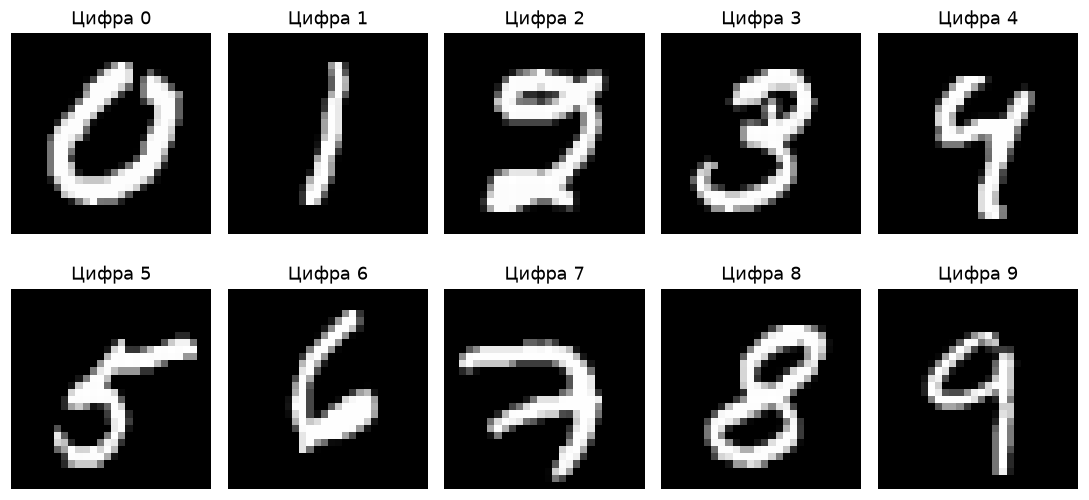

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for digit, ax in enumerate(axes.flat):
    index = np.flatnonzero(y_train_full == digit)[0]
    ax.imshow(X_train_full[index].reshape(28, 28), cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Цифра {digit}')
    ax.axis('off')
plt.tight_layout()
plt.show()


### 0.3. Подготовка массивов


In [4]:
X = np.concatenate([X_train_full, X_val], axis=0)
y = np.concatenate([y_train_full, y_val], axis=0)
X = X.reshape(len(X), -1).astype(np.float32) / 255.0
X_test_official = X_test_images.reshape(len(X_test_images), -1).astype(np.float32) / 255.0
print('Форма X:', X.shape)
print('Форма y:', y.shape)
print('Уникальные классы:', np.unique(y))
print('Минимум и максимум пикселей:', X.min(), X.max())
assert X.shape == (60000, 784)
assert X.min() >= 0 and X.max() <= 1


Форма X: (60000, 784)
Форма y: (60000,)
Уникальные классы: [0 1 2 3 4 5 6 7 8 9]
Минимум и максимум пикселей: 0.0 1.0


Я объединил обучающую и валидационную выборки и получил 60 000
изображений с 784 признаками. Значения пикселей перевёл в диапазон от 0 до 1;
официальные 10 000 тестовых изображений оставил для отдельной проверки в конце.


## Часть 1. Метод главных компонент

### Теоретическое введение: PCA

**Проблема:** У нас 784 признака (пикселя) на каждое изображение. Многие из них **коррелированы** (соседние пиксели часто имеют похожие значения), а некоторые **неинформативны** (например, углы картинки почти всегда чёрные).

**Идея PCA:** Найти такие **новые оси** (главные компоненты), вдоль которых данные **сильнее всего разбросаны**. Тогда:
- Несколько первых компонент опишут **большую часть** информации
- Остальные компоненты можно **отбросить** без существенной потери качества

### Математика PCA

Пусть у нас есть матрица данных $X \in \mathbb{R}^{n \times d}$ (n объектов, d признаков).

**Шаг 1. Центрирование.** Вычитаем среднее по каждому признаку:
$$ X_{centered} = X - \bar{X} $$
где $\bar{X}$ — вектор средних значений по каждому столбцу.

**Шаг 2. Матрица ковариации:**
$$ C = \frac{1}{n-1} X_{centered}^T X_{centered} \in \mathbb{R}^{d \times d} $$

**Шаг 3. Собственные векторы и значения.** Находим:
$$ C v_i = \lambda_i v_i $$
где $\lambda_1 \ge \lambda_2 \ge ... \ge \lambda_d$ — собственные значения, $v_i$ — собственные векторы.

**Шаг 4. Преобразование.** Новые координаты объекта:
$$ Y = X_{centered} \cdot V_k $$
где $V_k$ — матрица из первых $k$ собственных векторов.

### Важная связь: собственные числа и дисперсия

**Собственное число $\lambda_i$ равно дисперсии данных вдоль $i$-й главной компоненты.**

Доля объяснённой дисперсии для $k$ первых компонент:
$$ \text{Explained Variance Ratio} = \frac{\sum_{i=1}^{k} \lambda_i}{\sum_{i=1}^{d} \lambda_i} $$


### 1.1. Реализация my_PCA
Я вычитаю среднее по каждому признаку и выполняю SVD. Строки `Vt` задают новые оси,
а квадраты сингулярных чисел, поделённые на $(n-1)$, дают собственные значения.
SVD уже возвращает их в порядке убывания.


In [5]:
class my_PCA:
    def __init__(self, n_components=None):
        self.n_components = n_components
        self.components_ = None
        self.explained_variance_ = None
        self.mean_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        self.mean_ = X.mean(axis=0)
        centered = X - self.mean_
        _, s, Vt = np.linalg.svd(centered, full_matrices=False)
        count = len(s) if self.n_components is None else self.n_components
        if not 1 <= count <= len(s):
            raise ValueError('Неверное число компонент')
        self.components_ = Vt[:count]
        self.explained_variance_ = s[:count]**2 / (len(X) - 1)
        return self

    def transform(self, X):
        return (np.asarray(X) - self.mean_) @ self.components_.T

    def fit_transform(self, X):
        return self.fit(X).transform(X)


### 1.2. Сравнение со sklearn
Я сравнил реализации на первых 1 000 изображениях. Для sklearn выбрал полный SVD,
чтобы сравнивать одинаковые способы расчёта. Знак главной компоненты может отличаться:
ось можно направить в любую из двух сторон.


In [6]:
my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50, svd_solver='full')
X_check = X[:1000].astype(np.float64)
Y_my = my_pca.fit_transform(X_check)
Y_sk = sk_pca.fit_transform(X_check)

signs = np.sign(np.sum(my_pca.components_ * sk_pca.components_, axis=1))
signs[signs == 0] = 1
assert np.allclose(my_pca.explained_variance_, sk_pca.explained_variance_, atol=1e-8)
assert np.allclose(Y_my * signs, Y_sk, atol=1e-7)
print('Сумма собственных значений my_PCA:', round(my_pca.explained_variance_.sum(), 6))
print('Сумма собственных значений sklearn:', round(sk_pca.explained_variance_.sum(), 6))
print('Форма Y_my:', Y_my.shape, 'Форма Y_sk:', Y_sk.shape)
print('Проверки PCA пройдены.')


Сумма собственных значений my_PCA: 45.476761
Сумма собственных значений sklearn: 45.476761
Форма Y_my: (1000, 50) Форма Y_sk: (1000, 50)
Проверки PCA пройдены.


**Совпадают ли собственные значения?** Да, собственные значения совпали с точностью
до вычислительной погрешности. Координаты после учёта знаков осей тоже совпали.


### 1.3. Графики дисперсии
Для исследования дисперсии я обучил PCA на всех 60 000 изображениях.
На первом графике показан вклад каждой компоненты, на втором — их накопленный вклад.


PCA на всех данных: 10.04 с
Первые 15 компонент: 57.93% дисперсии
Для 95% нужно компонент: 154
Для 99% нужно компонент: 331


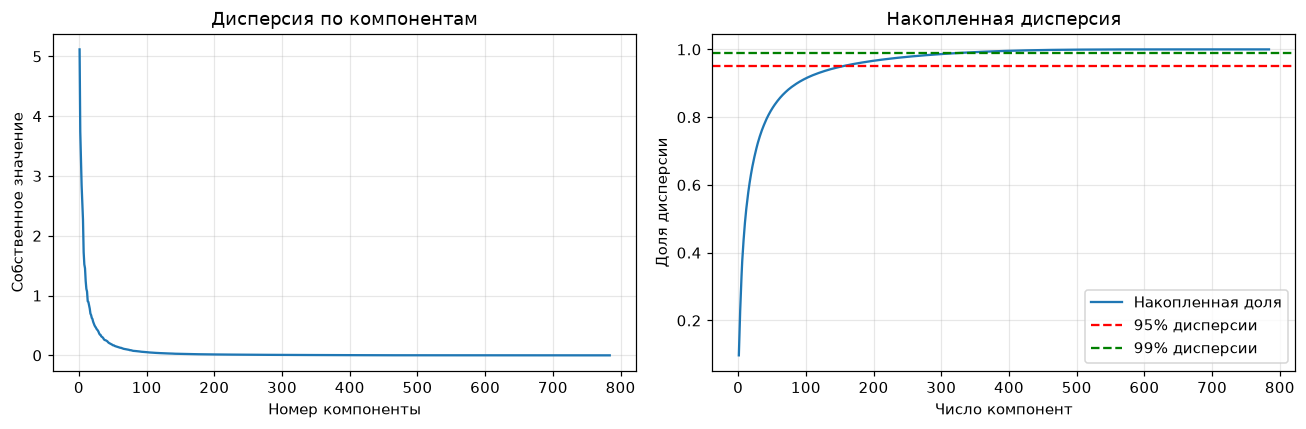

In [7]:
start = perf_counter()
pca_full = my_PCA().fit(X)
pca_full_seconds = perf_counter() - start
eigenvalues = pca_full.explained_variance_
cumulative = np.cumsum(eigenvalues) / eigenvalues.sum()
share15 = cumulative[14]
n95 = int(np.searchsorted(cumulative, 0.95) + 1)
n99 = int(np.searchsorted(cumulative, 0.99) + 1)
print(f'PCA на всех данных: {pca_full_seconds:.2f} с')
print(f'Первые 15 компонент: {share15:.2%} дисперсии')
print('Для 95% нужно компонент:', n95)
print('Для 99% нужно компонент:', n99)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
numbers = np.arange(1, len(eigenvalues) + 1)
axes[0].plot(numbers, eigenvalues)
axes[0].set(xlabel='Номер компоненты', ylabel='Собственное значение', title='Дисперсия по компонентам')
axes[1].plot(numbers, cumulative, label='Накопленная доля')
axes[1].axhline(0.95, color='red', linestyle='--', label='95% дисперсии')
axes[1].axhline(0.99, color='green', linestyle='--', label='99% дисперсии')
axes[1].set(xlabel='Число компонент', ylabel='Доля дисперсии', title='Накопленная дисперсия')
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Ответы на вопросы:**

1. Первые 15 компонент объясняют 57,93% дисперсии.
2. Для объяснения 95% нужны 154 компоненты.
3. Собственное число показывает, насколько сильно различаются объекты вдоль выбранной
   новой оси. Чем оно больше, тем больший разброс сохраняет эта компонента.
   Доля дисперсии не равна доле правильно распознанных цифр.


### 1.4. Цифры в первых двух компонентах
Я использовал первые две оси уже обученного PCA: повторное обучение дало бы тот же результат.
На графике показал 5 000 случайно выбранных точек, чтобы цифры было легче рассмотреть.


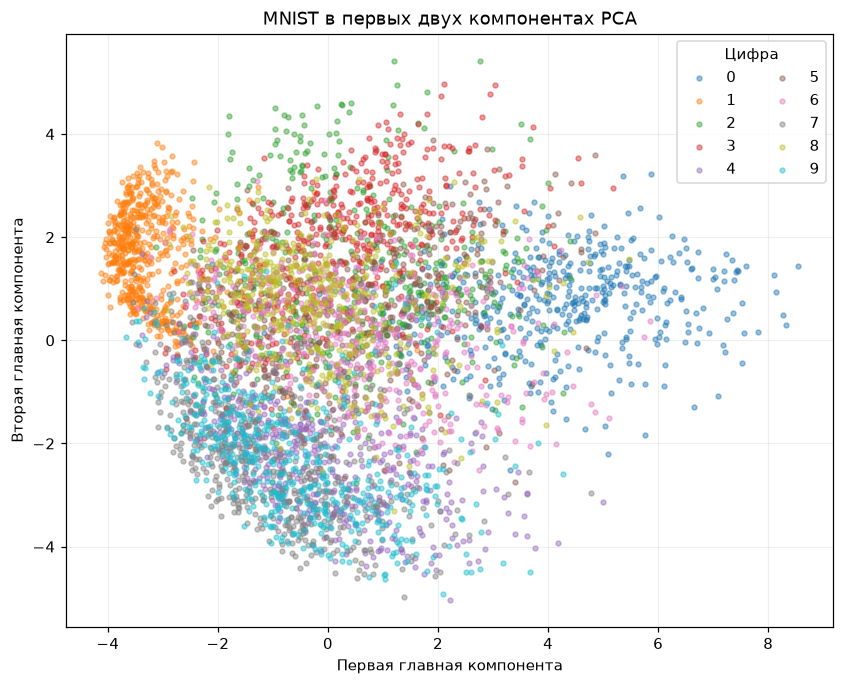

In [8]:
pca_2d = my_PCA(n_components=2)
pca_2d.mean_ = pca_full.mean_
pca_2d.components_ = pca_full.components_[:2]
pca_2d.explained_variance_ = pca_full.explained_variance_[:2]
Y_2d = pca_2d.transform(X)
plot_indices = np.random.default_rng(42).choice(len(X), 5000, replace=False)

plt.figure(figsize=(9, 7))
for digit in range(10):
    selected = plot_indices[y[plot_indices] == digit]
    plt.scatter(Y_2d[selected, 0], Y_2d[selected, 1], s=10,
                alpha=0.45, color=plt.get_cmap('tab10')(digit), label=str(digit))
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('MNIST в первых двух компонентах PCA')
plt.legend(title='Цифра', ncol=2)
plt.grid(alpha=0.2)
plt.show()


**Видны ли классы раздельно и какие цифры группируются вместе?**
Полного разделения нет. Единицы образуют заметную отдельную группу, нули тоже чаще находятся в одной области. Цифры 4, 7 и 9 сильно смешиваются между собой; в центральной части перекрываются и другие цифры. У похожих по форме изображений похожие яркости пикселей, поэтому их точки могут оказаться рядом. Две компоненты сохраняют только часть различий между картинками.
Кроме того, PCA не использует метки цифр: он ищет общий разброс данных, а не границы классов.

В итоге, я написал PCA и проверил его по sklearn.
Большую часть дисперсии можно сохранить с числом признаков намного меньше 784,
но двух компонент недостаточно для хорошего разделения всех цифр.


## Часть 2. Метод k-ближайших соседей

### Теоретическое введение: kNN

**Идея:** Объект относится к тому классу, к которому принадлежит **большинство** из его $k$ ближайших соседей в обучающей выборке.

**Алгоритм предсказания для объекта $x$:**
1. Найти расстояния от $x$ до всех объектов обучающей выборки
2. Выбрать $k$ объектов с наименьшими расстояниями
3. Найти самый частый класс среди этих $k$ объектов
4. Вернуть этот класс как предсказание

**Метрика расстояния:** Обычно используется **евклидово расстояние**:
$$ d(x, x') = \sqrt{\sum_{i=1}^{d} (x_i - x'_i)^2} $$


### 2.1. Реализация my_kNN
Я сохраняю обучающие объекты и при предсказании нахожу ближайшие к новому изображению.
Расстояния считаю матричными операциями небольшими порциями по 200 объектов.
Квадратный корень можно не извлекать: порядок соседей от этого не меняется.
При равном числе голосов выбирается меньшая цифра.


In [9]:
def vote(neighbor_labels):
    return np.array([np.bincount(row, minlength=10).argmax() for row in neighbor_labels])

class my_kNN:
    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=np.float64)
        self.y_train = np.asarray(y, dtype=int)
        if not 1 <= self.n_neighbors <= len(self.X_train):
            raise ValueError('Неверное число соседей')
        self.train_norms = np.sum(self.X_train**2, axis=1)
        return self

    def kneighbors(self, X):
        X = np.asarray(X, dtype=np.float64)
        neighbors = []
        for start in range(0, len(X), 200):
            batch = X[start:start + 200]
            distances = (np.sum(batch**2, axis=1)[:, None] + self.train_norms
                         - 2 * batch @ self.X_train.T)
            distances = np.maximum(distances, 0)
            indices = np.argsort(distances, axis=1, kind='stable')[:, :self.n_neighbors]
            neighbors.append(indices)
        return np.vstack(neighbors)

    def predict(self, X):
        indices = self.kneighbors(X)
        return vote(self.y_train[indices])


### 2.2. Проверка классификатора
Для экспериментов я взял 5 000 изображений, как разрешено в советах к заданию.
Выбрал их случайно с сохранением долей цифр и разделил на 3 500 обучающих и 1 500 проверочных.
Это одни и те же данные для всех сравнений ниже. Проверочная часть используется и при подборе
параметров, поэтому в конце я отдельно проверю выбранный вариант на официальной тестовой выборке.


In [10]:
X_small, _, y_small, _ = train_test_split(
    X, y, train_size=5000, random_state=42, stratify=y)
X_train, X_test, y_train, y_test = train_test_split(
    X_small, y_small, test_size=0.3, random_state=42, stratify=y_small)
print('Обучение:', X_train.shape, 'Проверка:', X_test.shape)

start = perf_counter()
my_knn = my_kNN(n_neighbors=5).fit(X_train, y_train)
y_pred_my = my_knn.predict(X_test)
time_original = perf_counter() - start
accuracy_my = accuracy_score(y_test, y_pred_my)
print(f'Точность my_kNN: {accuracy_my:.4f}')
print(f'Время fit + predict: {time_original:.3f} с')


Обучение: (3500, 784) Проверка: (1500, 784)
Точность my_kNN: 0.9227
Время fit + predict: 0.523 с


В итоге, я получил 92,27% правильных ответов.
Это больше 90% и намного выше случайного выбора одной из десяти цифр.


### 2.3. Сравнение со sklearn


In [11]:
sk_knn = KNeighborsClassifier(n_neighbors=5, algorithm='brute', metric='euclidean')
sk_knn.fit(X_train.astype(np.float64), y_train)
y_pred_sk = sk_knn.predict(X_test.astype(np.float64))
accuracy_sk = accuracy_score(y_test, y_pred_sk)
agreement = np.mean(y_pred_my == y_pred_sk)
print(f'Точность sklearn kNN: {accuracy_sk:.4f}')
print(f'Разница точностей: {abs(accuracy_my - accuracy_sk):.6f}')
print(f'Совпадение предсказаний: {agreement:.2%}')
assert np.array_equal(y_pred_my, y_pred_sk), 'Предсказания двух реализаций отличаются'
print('Проверка kNN пройдена.')


Точность sklearn kNN: 0.9227
Разница точностей: 0.000000
Совпадение предсказаний: 100.00%
Проверка kNN пройдена.


**Совпали ли результаты?** Да, на выбранной проверочной выборке совпали и точность,
и предсказания для каждого изображения.


### 2.4. Число соседей
Я проверил все значения из задания. Чтобы не искать соседей заново для каждого `k`,
сначала нашёл 30 ближайших, а затем брал первые 1, 3, 5 и так далее.


k =  1: accuracy = 0.9260
k =  3: accuracy = 0.9260
k =  5: accuracy = 0.9227
k =  7: accuracy = 0.9213
k = 10: accuracy = 0.9187
k = 15: accuracy = 0.9153
k = 20: accuracy = 0.9087
k = 30: accuracy = 0.8980


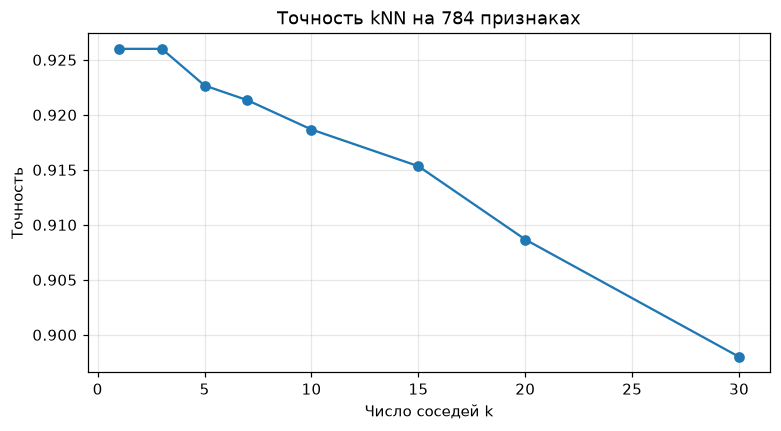

In [12]:
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
knn30 = my_kNN(n_neighbors=30).fit(X_train, y_train)
labels30 = y_train[knn30.kneighbors(X_test)]
accuracies = []
for k in k_values:
    prediction = vote(labels30[:, :k])
    score = accuracy_score(y_test, prediction)
    accuracies.append(score)
    print(f'k = {k:2d}: accuracy = {score:.4f}')

plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, 'o-')
plt.xlabel('Число соседей k')
plt.ylabel('Точность')
plt.title('Точность kNN на 784 признаках')
plt.grid(alpha=0.3)
plt.show()


**При каком k точность максимальна?** В моём эксперименте лучший результат получился
при **k = 1 и 3**: **92,60%**.
При маленьком `k` решение сильнее зависит от одного необычного или плохо написанного примера.
При слишком большом `k` в голосование попадают более далёкие объекты других классов.
Поэтому небольшое число соседей не обязательно хуже во всех случаях: это нужно проверять на данных.

Таким образом, я реализовал kNN и получил совпадение с готовой моделью.
Число соседей влияет на результат, поэтому его стоит подбирать, а не выбирать случайно.


## Часть 3. PCA и kNN вместе

### Теоретическое введение

**Проблемы kNN на полных данных:**
- **Вычислительная сложность:** расстояние считается по 784 признакам
- **"Проклятие размерности":** в высоких размерностях расстояния между точками становятся похожими
- **Шум:** неинформативные признаки мешают

**Решение:** Сначала уменьшить размерность с помощью PCA, потом обучить kNN.

**Вопрос для размышления:** Как вы думаете, улучшится ли качество? А скорость работы?


### 3.1. Число компонент и точность
Я обучил новый PCA только на обучающей части. Среднее и оси для проверочных изображений
взял из этой модели. PCA из части 1 здесь не использую, потому что он уже видел все 60 000 изображений.
Полное разложение достаточно найти один раз, а затем брать первые нужные компоненты.
Во всех вариантах этого пункта использовал 5 соседей.


PCA обучен на: (3500, 784)
Время обучения PCA: 0.581 с
Время преобразования в 784 компоненты: 0.086 с
Компонент:   1, accuracy: 0.2887, kNN: 0.366 с
Компонент:   2, accuracy: 0.4253, kNN: 0.387 с
Компонент:   5, accuracy: 0.7320, kNN: 0.381 с
Компонент:  10, accuracy: 0.8847, kNN: 0.381 с
Компонент:  15, accuracy: 0.9220, kNN: 0.389 с
Компонент:  20, accuracy: 0.9413, kNN: 0.379 с
Компонент:  30, accuracy: 0.9413, kNN: 0.369 с
Компонент:  50, accuracy: 0.9393, kNN: 0.372 с
Компонент:  75, accuracy: 0.9327, kNN: 0.368 с
Компонент: 100, accuracy: 0.9247, kNN: 0.380 с
Компонент: 200, accuracy: 0.9233, kNN: 0.393 с
Компонент: 300, accuracy: 0.9227, kNN: 0.501 с
Компонент: 500, accuracy: 0.9227, kNN: 0.431 с
Компонент: 784, accuracy: 0.9227, kNN: 0.494 с


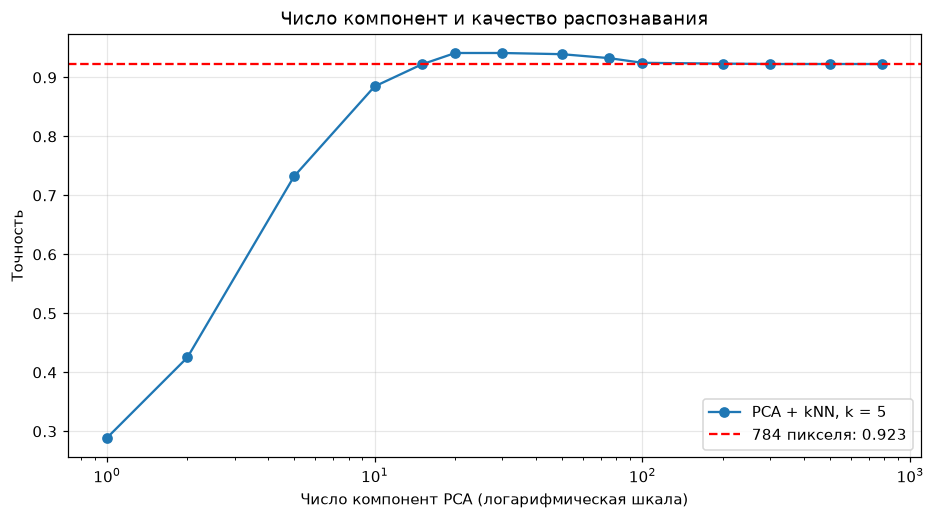

In [13]:
start = perf_counter()
pca_train = my_PCA().fit(X_train)
pca_fit_seconds = perf_counter() - start
start = perf_counter()
Z_train = pca_train.transform(X_train)
Z_test = pca_train.transform(X_test)
pca_transform_seconds = perf_counter() - start
print('PCA обучен на:', X_train.shape)
print(f'Время обучения PCA: {pca_fit_seconds:.3f} с')
print(f'Время преобразования в 784 компоненты: {pca_transform_seconds:.3f} с')

n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []
times = []
for n_comp in n_components_list:
    start = perf_counter()
    model = my_kNN(n_neighbors=5).fit(Z_train[:, :n_comp], y_train)
    prediction = model.predict(Z_test[:, :n_comp])
    elapsed = perf_counter() - start
    score = accuracy_score(y_test, prediction)
    accuracies_pca.append(score)
    times.append(elapsed)
    print(f'Компонент: {n_comp:3d}, accuracy: {score:.4f}, kNN: {elapsed:.3f} с')

assert abs(accuracies_pca[-1] - accuracy_my) < 1e-12
plt.figure(figsize=(10, 5))
plt.plot(n_components_list, accuracies_pca, 'o-', label='PCA + kNN, k = 5')
plt.axhline(accuracy_my, color='red', linestyle='--', label=f'784 пикселя: {accuracy_my:.3f}')
plt.xscale('log')
plt.xlabel('Число компонент PCA (логарифмическая шкала)')
plt.ylabel('Точность')
plt.title('Число компонент и качество распознавания')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Ответы на вопросы:**

1. При 5 соседях лучшая точность получилась для 20 и 30 компонент:
   94,13%.
2. Да, точность выросла с 92,27% до 94,13%: примерно на 1,87 процентного пункта.
3. При одной-двух компонентах теряется слишком много различий между цифрами.
   Например, разные изображения могут получить почти одинаковые новые координаты.
   Поэтому небольшая размерность не всегда означает хороший результат.

При всех 784 компонентах точность совпала с исходной: без отбрасывания компонент PCA
только поворачивает оси и вычитает среднее, а расстояния между объектами сохраняются.


### 3.2. Время работы
В предыдущем цикле я измерил время `fit + predict` моего kNN на готовых координатах PCA.
Обучение и преобразование PCA показаны отдельно и в этот график не входят.
Так я сравниваю именно работу kNN при разном числе признаков.


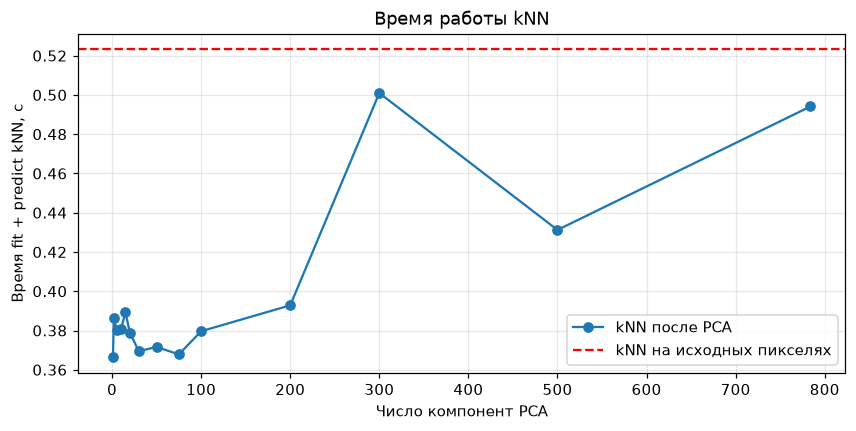

In [14]:
plt.figure(figsize=(9, 4))
plt.plot(n_components_list, times, 'o-', label='kNN после PCA')
plt.axhline(time_original, color='red', linestyle='--', label='kNN на исходных пикселях')
plt.xlabel('Число компонент PCA')
plt.ylabel('Время fit + predict kNN, с')
plt.title('Время работы kNN')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Как меняется время и почему?** В сохранённом запуске при 20 компонентах kNN занял около 0,379 с, а при 784 компонентах — 0,494 с. В целом при меньшей размерности он работал быстрее, но график получился не строго возрастающим.
При меньшем числе признаков нужно сделать меньше действий для расчёта расстояний.
Но поиск и сортировка соседей всё равно нужны, поэтому ускорение не прямо пропорционально
числу компонент. Это один замер для каждого варианта; время зависит и от компьютера.
Для полного времени работы ещё нужно учитывать обучение PCA и преобразование данных.


### 3.3. Совместный перебор параметров
Я проверил все 35 сочетаний числа компонент и числа соседей.
Для каждого числа компонент один раз нашёл 10 соседей, затем использовал нужную часть списка.


Лучший вариант: PCA = 20, k = 5, accuracy = 0.9413
Худший вариант: PCA = 5, k = 1, accuracy = 0.6820


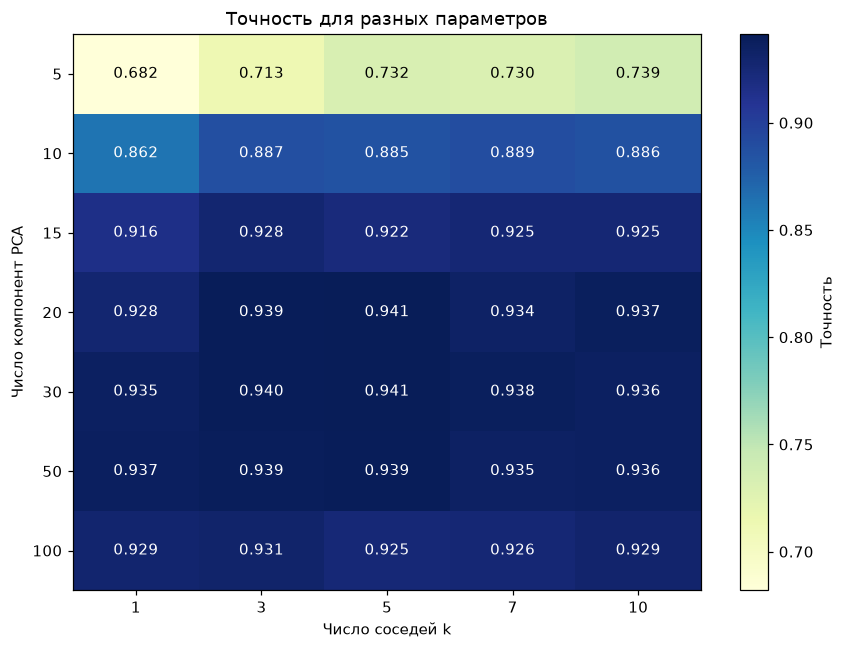

In [15]:
n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]
accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))
for i, n_comp in enumerate(n_components_grid):
    model = my_kNN(n_neighbors=max(k_grid)).fit(Z_train[:, :n_comp], y_train)
    neighbor_labels = y_train[model.kneighbors(Z_test[:, :n_comp])]
    for j, k in enumerate(k_grid):
        prediction = vote(neighbor_labels[:, :k])
        accuracy_matrix[i, j] = accuracy_score(y_test, prediction)

best_i, best_j = np.unravel_index(np.argmax(accuracy_matrix), accuracy_matrix.shape)
worst_i, worst_j = np.unravel_index(np.argmin(accuracy_matrix), accuracy_matrix.shape)
best_n, best_k_joint = n_components_grid[best_i], k_grid[best_j]
print(f'Лучший вариант: PCA = {best_n}, k = {best_k_joint}, accuracy = {accuracy_matrix.max():.4f}')
print(f'Худший вариант: PCA = {n_components_grid[worst_i]}, k = {k_grid[worst_j]}, '
      f'accuracy = {accuracy_matrix.min():.4f}')

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(accuracy_matrix, cmap='YlGnBu', aspect='auto')
ax.set_xticks(range(len(k_grid)), labels=k_grid)
ax.set_yticks(range(len(n_components_grid)), labels=n_components_grid)
middle = (accuracy_matrix.min() + accuracy_matrix.max()) / 2
for i in range(len(n_components_grid)):
    for j in range(len(k_grid)):
        ax.text(j, i, f'{accuracy_matrix[i, j]:.3f}', ha='center', va='center',
                color='white' if accuracy_matrix[i, j] > middle else 'black')
ax.set(xlabel='Число соседей k', ylabel='Число компонент PCA', title='Точность для разных параметров')
fig.colorbar(im, ax=ax, label='Точность')
plt.tight_layout()
plt.show()


**Ответы на вопросы:**

1. Лучший результат: 20 компонент и 5 соседей — 94,13%.
   Такой же максимум дали 30 компонент и 5 соседей; я выбрал 20 компонент, потому что их меньше.
2. Худший результат: 5 компонент и 1 сосед — 68,20%.
3. Да. Например, при 20 компонентах и 5 соседях получилось 94,13%, а без PCA при тех же 5 соседях — 92,27%. Это показывает, что сохранение всех пикселей не обязательно
   даёт лучший результат: PCA может убрать различия, которые мешают искать похожие цифры.
   При этом сами компоненты подбираются по разбросу данных, а не по правильным ответам.

Лучшие параметры здесь относятся к выбранным 5 000 изображениям и проверенной сетке,
а не являются единственными лучшими параметрами для всего MNIST.


## Выводы
В ходе выполнения данной работы я изучил PCA, который заменяет исходные признаки новыми осями и позволяет
оставить направления с наибольшим разбросом данных.
Я написал свою реализацию через SVD и проверил, что она даёт те же результаты, что и sklearn.
Для MNIST первые 15 компонент сохранили 57,93% дисперсии, а для 95% потребовались 154 компоненты.
Также я реализовал kNN: он находит похожие обучающие изображения и выбирает цифру большинством голосов соседей.
Его плюс - понятный принцип работы, а минусы - необходимость хранить обучающие данные и считать много расстояний.
На моей проверочной выборке исходный kNN с пятью соседями дал 92,27% правильных ответов.
Лучшим сочетанием в общей сетке стало 20 компонент и 5 соседей - 94,13%, поэтому для этого эксперимента я выбрал именно его,
но для другой выборки лучший вариант может измениться.
Я увидел, что при слишком сильном уменьшении размерности теряются важные детали цифр,
а при умеренном уменьшении можно сократить вычисления и сохранить хорошую точность.
Самым сложным этапом для меня была работа с размерами матриц и проверка того,
что PCA для классификации обучается только на обучающих изображениях.
Самым интересным было сравнить цифры в двух компонентах и увидеть на тепловой карте,
как число компонент и соседей вместе меняют результат.
